# Phase 3: Exploratory Risk & Return Analytics
วิเคราะห์ผลตอบแทนรายวัน, ความผันผวนต่อปี, Sharpe Ratio, Maximum Drawdown และ Correlation ของหุ้นไทยทั้ง 17 ตัว

In [2]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.data import load_price_matrix, get_tickers_info

# 1. โหลด Price Matrix จากฐานข้อมูล SQLite ที่เราสร้างไว้ใน Phase 2
prices = load_price_matrix()
print("โหลดข้อมูลสำเร็จ! ขนาด:", prices.shape)
prices.head()

โหลดข้อมูลสำเร็จ! ขนาด: (2430, 17)


ticker,ADVANC.BK,AOT.BK,BBL.BK,BDMS.BK,BH.BK,BJC.BK,CPALL.BK,CPN.BK,DELTA.BK,KBANK.BK,KTB.BK,MINT.BK,PTT.BK,PTTEP.BK,SCC.BK,TDEX.BK,TTB.BK
date,,,,,,,,,,,,,,,,,
2015-01-05,141.822464,24.233814,117.724190,13.616664,105.018890,29.082920,34.182598,35.039536,5.396035,142.203079,12.433333,24.699152,17.544947,59.177643,303.784302,6.057407,1.556339
2015-01-06,140.683350,24.145048,117.414436,13.465370,105.777153,28.550150,33.981529,35.039536,5.239628,138.324875,12.039516,23.726740,17.990532,59.177643,298.383606,6.039342,1.534263
2015-01-07,144.100708,25.121504,118.653618,13.541018,105.777153,29.263126,34.785820,35.236385,5.787051,140.910355,12.545852,24.115705,18.603210,58.901134,298.383606,6.081491,1.567377
2015-01-08,142.392044,25.654114,118.963409,14.070553,106.535408,29.615690,34.785820,35.630089,5.787051,147.374146,12.714630,25.088114,18.937405,60.836838,302.434113,6.165791,1.611528
2015-01-09,141.252884,25.831652,117.724190,13.843608,105.018890,29.443323,33.981529,35.826942,5.591542,148.020538,12.658370,25.282597,18.826004,62.219498,306.484619,6.183853,1.611528


In [3]:
# คำนวณ Daily Simple Return: (P_t - P_{t-1}) / P_{t-1}
# .dropna() เพื่อตัดแถววันแรกสุดทิ้งเพราะยังไม่มีวันก่อนหน้าให้เทียบ
returns = prices.pct_change().dropna()

print("ขนาด Returns Matrix:", returns.shape)
returns.head()

ขนาด Returns Matrix: (2429, 17)


ticker,ADVANC.BK,AOT.BK,BBL.BK,BDMS.BK,BH.BK,BJC.BK,CPALL.BK,CPN.BK,DELTA.BK,KBANK.BK,KTB.BK,MINT.BK,PTT.BK,PTTEP.BK,SCC.BK,TDEX.BK,TTB.BK
date,,,,,,,,,,,,,,,,,
2015-01-06,-0.008032,-0.003663,-0.002631,-0.011111,0.007220,-0.018319,-0.005882,0.000000,-0.028985,-0.027272,-0.031674,-0.039370,0.025397,0.000000,-0.017778,-0.002982,-0.014184
2015-01-07,0.024291,0.040441,0.010554,0.005618,0.000000,0.024973,0.023668,0.005618,0.104477,0.018691,0.042056,0.016394,0.034056,-0.004673,0.000000,0.006979,0.021583
2015-01-08,-0.011857,0.021201,0.002611,0.039106,0.007168,0.012048,0.000000,0.011173,0.000000,0.045872,0.013453,0.040323,0.017964,0.032864,0.013575,0.013862,0.028169
2015-01-09,-0.008000,0.006920,-0.010417,-0.016129,-0.014235,-0.005820,-0.023121,0.005525,-0.033784,0.004386,-0.004425,0.007752,-0.005883,0.022727,0.013393,0.002929,0.000000
2015-01-12,-0.004032,0.000000,-0.010526,0.000000,0.007220,-0.012241,0.011834,0.000000,-0.006993,-0.008734,-0.004444,-0.023077,-0.014793,-0.017778,0.000000,0.003895,0.027397


### Notes: สูตรคำนวณสถิติหลักรายหุ้น (10 ปี: 2015-2024)
- **Annualized Return**: `mean_daily_return * 252`
- **Annualized Volatility**: `std_daily_return * sqrt(252)`
- **Sharpe Ratio**: `(Ann_Return - Rf) / Ann_Vol` (ใช้ Rf = 2.5% ตั๋วเงินคลังไทย)
- **Max Drawdown (MDD)**:
  - `wealth = (1 + returns).cumprod()` (มูลค่าพอร์ตสะสมเริ่มจาก 1 บาท)
  - `peak = wealth.cummax()` (จุดสูงสุดในอดีตที่เคยไปถึง)
  - `dd = (wealth - peak) / peak` (การดิ่งลงจากยอดดอยเดิม)
  - `mdd = dd.min()` (จุดที่ขาดทุนลึกที่สุดในประวัติศาสตร์)

In [4]:
# 1. คำนวณค่าสถิติหลักของแต่ละหุ้น
risk_free_rate = 0.025  # 2.5% Thai Risk-Free Rate

ann_return = returns.mean() * 252
ann_vol = returns.std() * np.sqrt(252)
sharpe_ratio = (ann_return - risk_free_rate) / ann_vol

# 2. คำนวณ Max Drawdown (MDD) รายหุ้น
wealth_index = (1 + returns).cumprod()
running_peaks = wealth_index.cummax()
drawdowns = (wealth_index - running_peaks) / running_peaks
max_drawdowns = drawdowns.min()

# 3. รวมเป็นตารางสรุป และดึง Sector มาประกบ
tickers_df = get_tickers_info()
summary = pd.DataFrame({
    'Ann_Return': ann_return,
    'Ann_Volatility': ann_vol,
    'Sharpe_Ratio': sharpe_ratio,
    'Max_Drawdown': max_drawdowns
}).reset_index()

# ผสานข้อมูล Sector เข้ามาดูคู่กัน
summary = summary.merge(tickers_df[['ticker', 'sector']], on='ticker', how='left')

# จัดรูปแบบตัวเลขให้อ่านง่าย และเรียงลำดับจาก Sharpe สูงสุดไปต่ำสุด
summary_sorted = summary.sort_values(by='Sharpe_Ratio', ascending=False).reset_index(drop=True)

summary_display = summary_sorted.copy()
summary_display['Ann_Return'] = summary_display['Ann_Return'].map('{:.2%}'.format)
summary_display['Ann_Volatility'] = summary_display['Ann_Volatility'].map('{:.2%}'.format)
summary_display['Sharpe_Ratio'] = summary_display['Sharpe_Ratio'].map('{:.2f}'.format)
summary_display['Max_Drawdown'] = summary_display['Max_Drawdown'].map('{:.2%}'.format)

print("=== ตารางสรุป Return, Risk และ Sharpe Ratio ย้อนหลัง 10 ปี (เรียงตาม Sharpe) ===")
summary_display

=== ตารางสรุป Return, Risk และ Sharpe Ratio ย้อนหลัง 10 ปี (เรียงตาม Sharpe) ===


,ticker,Ann_Return,Ann_Volatility,Sharpe_Ratio,Max_Drawdown,sector
0,DELTA.BK,50.06%,56.13%,0.85,-66.45%,Electronic Components
1,AOT.BK,12.35%,25.38%,0.39,-41.15%,Transport
2,PTTEP.BK,11.60%,33.81%,0.27,-64.78%,Energy
3,ADVANC.BK,8.52%,22.84%,0.26,-46.58%,ICT
4,BH.BK,9.67%,28.60%,0.25,-60.86%,Healthcare
5,BDMS.BK,7.94%,23.40%,0.23,-33.36%,Healthcare
6,PTT.BK,8.43%,27.33%,0.22,-52.22%,Energy
7,CPN.BK,8.36%,28.80%,0.20,-60.86%,Property
8,CPALL.BK,6.72%,21.50%,0.20,-38.67%,Commerce
9,KTB.BK,6.61%,23.89%,0.17,-54.96%,Banking


### Notes: Findings สำคัญจากข้อมูลย้อนหลัง 10 ปี (2015-2024)
1. **พลังของการกระจายความเสี่ยง (Diversification Effect):**
   - หุ้นรายตัวเกือบทั้งหมดมีความผันผวนสูงมาก (21% - 56% ต่อปี)
   - แต่ดัชนี `TDEX.BK` (พอร์ตหุ้น SET50 รวมกัน) ความผันผวนเหลือเพียง **14.79%** เท่านั้น! ต่ำกว่าหุ้นเดี่ยวเกือบทุกตัว สะท้อนชัดเจนว่าการถือหุ้นหลายตัวช่วยขจัดความผันผวนเฉพาะตัวออกไปได้จริง
2. **กรณีศึกษา DELTA.BK (Overfitting Trap):**
   - ผลตอบแทนสูงเว่อร์ (50.06% ต่อปี) ทำให้ Sharpe Ratio พุ่งไปที่ 0.85
   - แต่ความผันผวนก็มหาศาล (56.13%) และ Max Drawdown เคยดิ่งลงถึง **-66.45%**
   - ถ้าเอาโมเดล Max-Sharpe ธรรมดามาจัดพอร์ต โมเดลจะทุ่มน้ำหนักให้ DELTA เกินครึ่ง ซึ่งเสี่ยงพอร์ตพังเมื่อหุ้นหมดรอบ
3. **หุ้นที่ Sharpe ติดลบ (แพ้ดอกเบี้ยเงินฝาก):**
   - `SCC.BK` (Sharpe -0.33) และ `BJC.BK` (Sharpe -0.02) ผลตอบแทน 10 ปีต่ำกว่า 2.5% แสดงว่าการถือหุ้นกลุ่มนี้ในอดีตได้ผลตอบแทนไม่คุ้มค่าความเสี่ยงที่แบกรับ
4. **กลุ่มธนาคาร (Banking Sector):**
   - หุ้นแบงก์ (`KBANK`, `BBL`, `KTB`, `TTB`) ให้ผลตอบแทนเฉลี่ย 3% - 6% แต่มี Max Drawdown ลึกมาก (-54% ถึง -74%) ในช่วงวิกฤตเศรษฐกิจและ COVID-19

### Step 3.4: พล็อต Correlation Heatmap & Drawdown Chart
- **Correlation Matrix**: ดูความสัมพันธ์รายคู่ หุ้นที่มี Correlation ต่ำจะช่วยลดความเสี่ยงพอร์ตได้ดีที่สุด
- **Drawdown Chart**: กราฟแสดงการดิ่งลงจากจุดสูงสุด เพื่อดูพฤติกรรมช่วงวิกฤต COVID-19 (มี.ค. 2020)

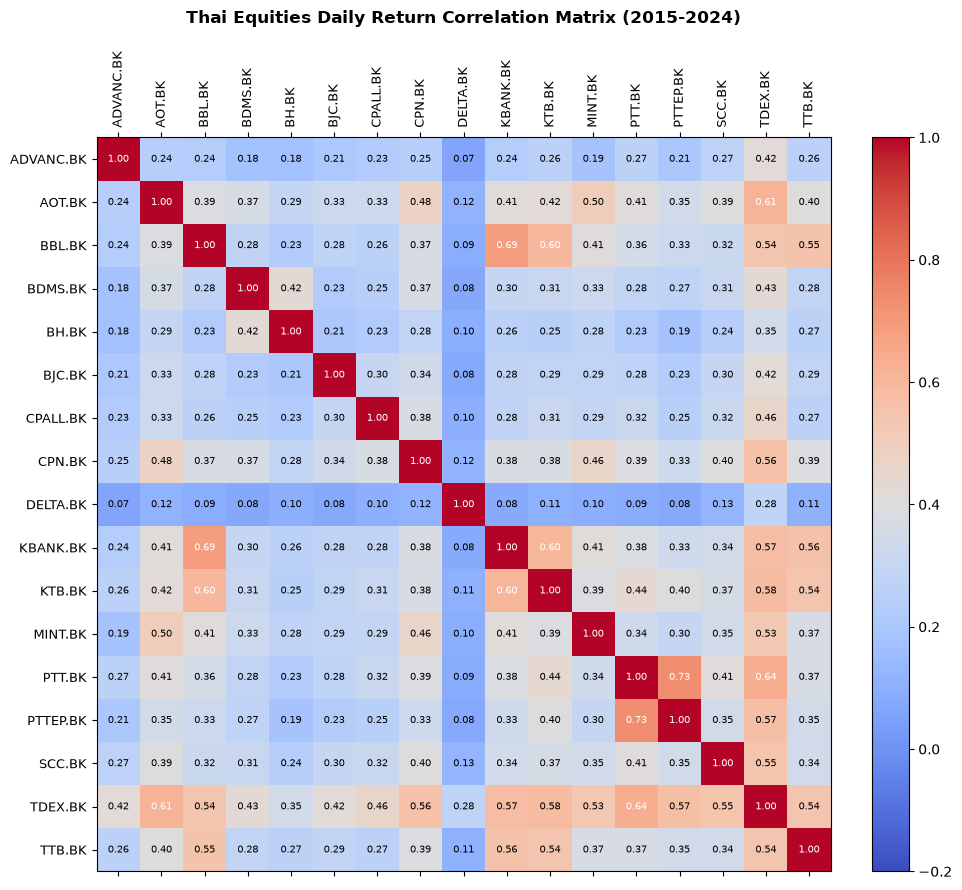

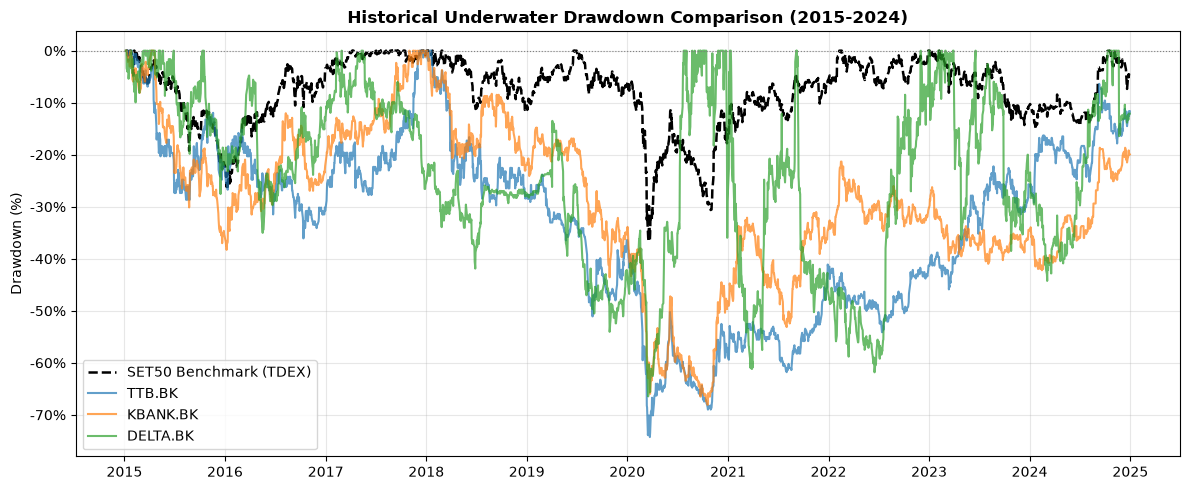

In [5]:
# 1. คำนวณ Correlation Matrix
corr_matrix = returns.corr()

# 2. พล็อต Correlation Heatmap
fig, ax = plt.subplots(figsize=(11, 9))
cax = ax.matshow(corr_matrix, cmap='coolwarm', vmin=-0.2, vmax=1.0)
fig.colorbar(cax, fraction=0.046, pad=0.04)

tickers = corr_matrix.columns
ax.set_xticks(range(len(tickers)))
ax.set_yticks(range(len(tickers)))
ax.set_xticklabels(tickers, rotation=90, fontsize=9)
ax.set_yticklabels(tickers, fontsize=9)

# ใส่ตัวเลข correlation ลงในช่อง
for i in range(len(tickers)):
    for j in range(len(tickers)):
        val = corr_matrix.iloc[i, j]
        ax.text(j, i, f"{val:.2f}", ha='center', va='center',
                color='white' if abs(val) > 0.6 else 'black', fontsize=7.5)

plt.title("Thai Equities Daily Return Correlation Matrix (2015-2024)", pad=20, fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# 3. พล็อต Underwater Drawdown Chart ของกลุ่มธนาคาร vs Benchmark (TDEX)
plt.figure(figsize=(12, 5))
plt.plot(drawdowns['TDEX.BK'], label='SET50 Benchmark (TDEX)', color='black', linewidth=1.8, linestyle='--')
plt.plot(drawdowns['TTB.BK'], label='TTB.BK', alpha=0.7)
plt.plot(drawdowns['KBANK.BK'], label='KBANK.BK', alpha=0.7)
plt.plot(drawdowns['DELTA.BK'], label='DELTA.BK', alpha=0.7)
plt.axhline(0, color='gray', linestyle=':', linewidth=0.8)
plt.title("Historical Underwater Drawdown Comparison (2015-2024)", fontsize=12, fontweight='bold')
plt.ylabel("Drawdown (%)")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
plt.legend(loc='lower left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()